In [6]:
import sys
sys.path.insert(0, "..")

import json
from pathlib import Path
import torch
import numpy as np

from interpretability.utils import load_model, load_dataset, compute_avg_attn, plot_attention
from generators.levels import generate_for_level

In [7]:
TASK = "level1_lookup_pos2_seed0_model-2l-8h-512e"  # change to any model
MODEL_BASE_PATH = Path("/nlpscratch/home/ralvarez/memorization-llms/saved_models")
UNSEEN_SEED = 42  # different seed for new conditioned data

In [8]:
with open(MODEL_BASE_PATH / TASK / "metadata.json") as f:
    metadata = json.load(f)

model = load_model(metadata["model_path"])
train_ids = load_dataset(metadata["dataset_path"])

# Extract dataset params from metadata
dataset_cfg = metadata["dataset_metadata"]
vocab_size  = dataset_cfg["vocab_size"]
prefix_len  = dataset_cfg["prefix_len"]
seq_len = dataset_cfg["seq_len"]
num_samples = dataset_cfg["num_samples"]
target_level = dataset_cfg["target_level"]
aggregation  = dataset_cfg["aggregation"]

print(f"Model: {TASK}")
print(f"Level: {target_level}, Aggregation: {aggregation}")
print(f"seq_len={seq_len}, prefix_len={prefix_len}, vocab_size={vocab_size}")

Model: level1_lookup_pos2_seed0_model-2l-8h-512e
Level: 1, Aggregation: lookup
seq_len=100, prefix_len=50, vocab_size=100


In [9]:
def generate_random_sequences(input_ids, vocab_size, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    return torch.randint(0, vocab_size, input_ids.shape, dtype=torch.int64)

random_ids = generate_random_sequences(train_ids, vocab_size=vocab_size, seed=0)

In [11]:
# Extract level-specific kwargs from metadata
level_kwargs = {}
for key in ["pos", "strategy", "lookback", "modulus", "polynomial_degree", "prime_modulus"]:
    if key in dataset_cfg:
        level_kwargs[key] = dataset_cfg[key]

# Generate fresh data with same condition structure but different seed
unseen_array = generate_for_level(
    level=target_level,
    num_samples=num_samples,
    seq_len=seq_len,
    vocab_size=vocab_size,
    aggregation=aggregation,
    seed=UNSEEN_SEED,
    prefix_len=prefix_len,
    random_prefix=dataset_cfg.get("random_prefix", True),
    **level_kwargs,
)
unseen_ids = torch.from_numpy(unseen_array.astype(np.int64))
print(f"Generated {unseen_ids.shape[0]} unseen conditioned sequences")

Generated 6000 unseen conditioned sequences


In [12]:
print("Computing attention on random sequences...")
attn_random = compute_avg_attn(model, random_ids)

print("Computing attention on unseen conditioned sequences...")
attn_unseen = compute_avg_attn(model, unseen_ids)

Computing attention on random sequences...
Computing attention on unseen conditioned sequences...


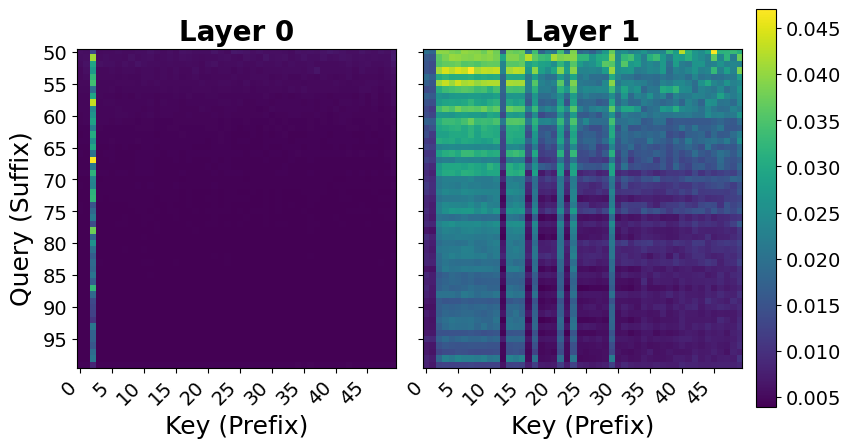

In [13]:
# --- Random sequences ---
plot_attention(attn_random)

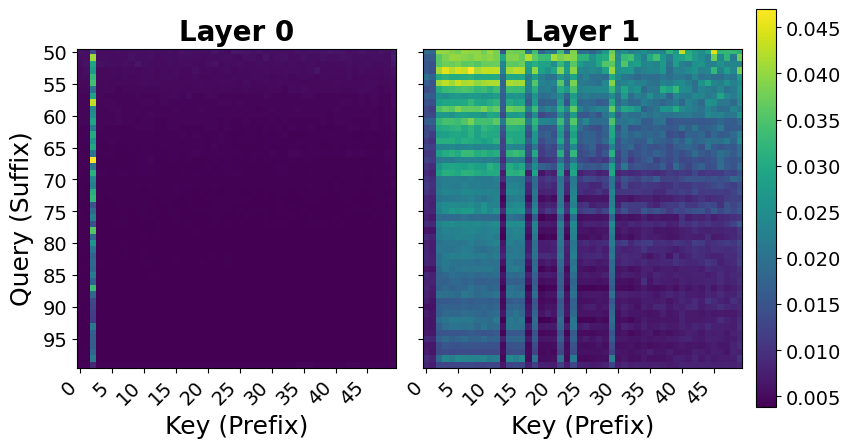

In [14]:
# --- Unseen conditioned sequences ---
plot_attention(attn_unseen)

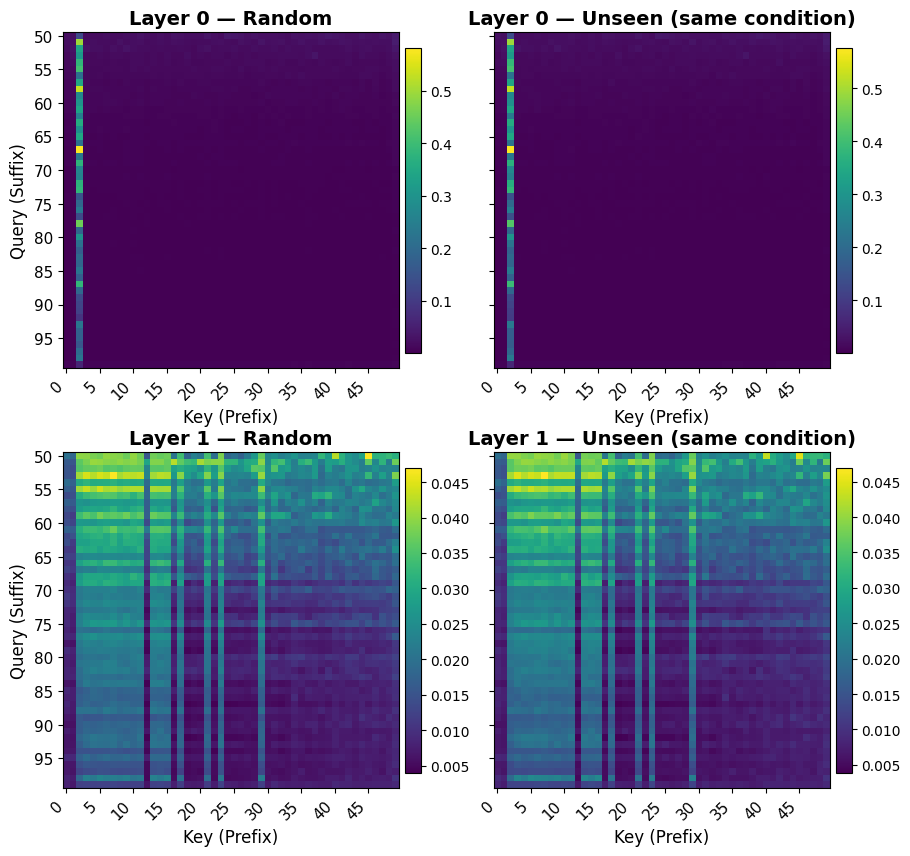

In [15]:
import matplotlib.pyplot as plt

def plot_attention_comparison(attn_a, attn_b, label_a="Random", label_b="Unseen (same condition)",
                               layers=None, query_range=(50, 100), key_range=(0, 50),
                               tick_step=5, cmap="viridis", reduce="max"):
    """Side-by-side comparison of two attention maps, one row per layer."""

    def to_np(x):
        return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)

    def agg_heads(x, mode):
        if mode == "mean":   return x.mean(axis=0)
        if mode == "median": return np.median(x, axis=0)
        if mode == "max":    return x.max(axis=0)
        raise ValueError('reduce must be "mean", "median", or "max"')

    n_layers, n_heads = attn_a.shape[:2]
    q0, q1 = query_range
    k0, k1 = key_range

    if layers is None:
        layers = list(range(n_layers))
    elif isinstance(layers, int):
        layers = [layers]

    q_ticks  = list(range(0, q1 - q0, tick_step))
    k_ticks  = list(range(0, k1 - k0, tick_step))
    q_labels = [str(q0 + i) for i in q_ticks]
    k_labels = [str(k0 + i) for i in k_ticks]

    nrows = len(layers)
    fig, axes = plt.subplots(
        nrows, 2,
        figsize=(9.0, 4.2 * nrows),
        sharey="row",
        constrained_layout=True,
    )
    if nrows == 1:
        axes = [axes]  # make iterable

    for row, L in enumerate(layers):
        for col, (attn, label) in enumerate([(attn_a, label_a), (attn_b, label_b)]):
            head_stack = np.stack(
                [to_np(attn[L, h, q0:q1, k0:k1]) for h in range(n_heads)], axis=0
            )
            img = agg_heads(head_stack, reduce)
            ax = axes[row][col]
            im = ax.imshow(img, cmap=cmap, aspect="equal")
            ax.set_title(f"Layer {L} — {label}", fontsize=14, fontweight="bold")
            ax.set_xlabel("Key (Prefix)", fontsize=12)
            ax.set_xticks(k_ticks)
            ax.set_xticklabels(k_labels, fontsize=11, rotation=45, ha="right")
            ax.set_yticks(q_ticks)
            ax.set_yticklabels(q_labels, fontsize=11)
            fig.colorbar(im, ax=ax, shrink=0.88, pad=0.02)

        axes[row][0].set_ylabel("Query (Suffix)", fontsize=12)

    plt.show()


plot_attention_comparison(attn_random, attn_unseen)